# B3 – Histogram dan Perbaikan Citra


## Langkah 3.1 – Lembar Hitung Manual

Diberikan citra 3-bit ($L = 8$, aras intensitas $r \in \{0, 1, 2, 3, 4, 5, 6, 7\}$) berukuran $4 \times 4$ ($N = 16$ piksel):

$$M = \begin{bmatrix} 1 & 2 & 2 & 3 \\ 2 & 2 & 3 & 3 \\ 1 & 2 & 3 & 4 \\ 2 & 3 & 3 & 2 \end{bmatrix}$$

---

### a) Histogram $M$

Frekuensi kemunculan setiap aras keabuan $r$:
- $r = 0$: $n_0 = 0$
- $r = 1$: $n_1 = 2$
- $r = 2$: $n_2 = 7$
- $r = 3$: $n_3 = 6$
- $r = 4$: $n_4 = 1$
- $r = 5, 6, 7$: $n_5 = n_6 = n_7 = 0$

Total piksel $N = 2 + 7 + 6 + 1 = 16$.

---

### b) Peregangan Kontras (*Contrast Stretching*) ke Rentang [0, 7]

Rumus transformasi peregangan kontras linier:

$$s = \text{round}\left( \frac{r - r_{\min}}{r_{\max} - r_{\min}} \times (L - 1) \right)$$

Dari matriks $M$, nilai minimum $r_{\min} = 1$ dan nilai maksimum $r_{\max} = 4$. Dengan $L - 1 = 7$:
- $r = 1 \implies s = \text{round}\left(\frac{1 - 1}{4 - 1} \times 7\right) = 0$
- $r = 2 \implies s = \text{round}\left(\frac{2 - 1}{3} \times 7\right) = \text{round}(2{,}33) = 2$
- $r = 3 \implies s = \text{round}\left(\frac{3 - 1}{3} \times 7\right) = \text{round}(4{,}67) = 5$
- $r = 4 \implies s = \text{round}\left(\frac{4 - 1}{3} \times 7\right) = 7$

Matriks hasil peregangan kontras:

$$M_{\text{stretch}} = \begin{bmatrix} 0 & 2 & 2 & 5 \\ 2 & 2 & 5 & 5 \\ 0 & 2 & 5 & 7 \\ 2 & 5 & 5 & 2 \end{bmatrix}$$

---

### c) Ekualisasi Histogram (*Histogram Equalization*)

Tabel perhitungan ekualisasi histogram ($N = 16, L - 1 = 7$):

| $r$ | $n_r$ | $P(r) = n_r / N$ | $CDF(r) = \sum P(r)$ | $7 \times CDF$ | $s = \text{round}(7 \times CDF)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | 0 | 0/16 = 0,0000 | 0,0000 | 0,00 | 0 |
| 1 | 2 | 2/16 = 0,1250 | 0,1250 | 0,88 | 1 |
| 2 | 7 | 7/16 = 0,4375 | 0,5625 | 3,94 | 4 |
| 3 | 6 | 6/16 = 0,3750 | 0,9375 | 6,56 | 7 |
| 4 | 1 | 1/16 = 0,0625 | 1,0000 | 7,00 | 7 |
| 5 | 0 | 0 | 1,0000 | 7,00 | 7 |
| 6 | 0 | 0 | 1,0000 | 7,00 | 7 |
| 7 | 0 | 0 | 1,0000 | 7,00 | 7 |

Pemetaan aras keabuan:
- $r = 1 \mapsto s = 1$
- $r = 2 \mapsto s = 4$
- $r = 3 \mapsto s = 7$
- $r = 4 \mapsto s = 7$ *(mengalami penggabungan / merging dengan r=3)*

Matriks hasil ekualisasi:

$$M_{\text{eq}} = \begin{bmatrix} 1 & 4 & 4 & 7 \\ 4 & 4 & 7 & 7 \\ 1 & 4 & 7 & 7 \\ 4 & 7 & 7 & 4 \end{bmatrix}$$

---

### d) Operasi Titik pada Citra 8-bit
1. **Citra Negatif** untuk $r = 60$:
   $$s = 255 - r = 255 - 60 = \mathbf{195}$$
2. **Peregangan Kontras** $s = 1{,}4\,r - 30$ (dengan clipping $[0, 255]$):
   - Untuk $r = 120$:
     $$s = 1{,}4(120) - 30 = 168 - 30 = \mathbf{138}$$
   - Untuk $r = 210$:
     $$s = 1{,}4(210) - 30 = 294 - 30 = 264 \xrightarrow{\text{clipping}} \mathbf{255}$$
3. **Koreksi Gamma** $s = 255 \times \left(\frac{r}{255}\right)^\gamma$ untuk $r = 100$:
   - $\gamma = 0{,}6$ (mencerahkan):
     $$s = 255 \times \left(\frac{100}{255}\right)^{0{,}6} \approx 255 \times (0{,}3922)^{0{,}6} = 255 \times 0{,}5703 \approx \mathbf{145{,}42}$$
   - $\gamma = 1{,}8$ (menggelapkan):
     $$s = 255 \times \left(\frac{100}{255}\right)^{1{,}8} \approx 255 \times (0{,}3922)^{1{,}8} = 255 \times 0{,}1855 \approx \mathbf{47{,}29}$$

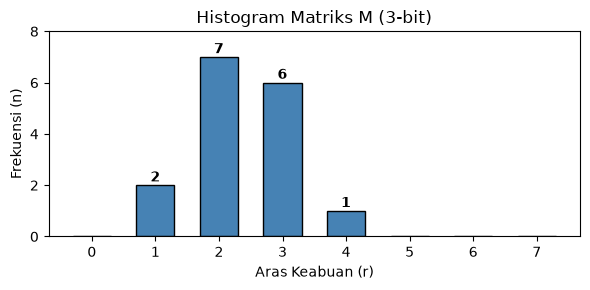

Matriks Hasil Peregangan Kontras [0, 7]:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]

Matriks Hasil Ekualisasi Histogram:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]

d) Operasi Titik 8-bit:
1. Negatif (r=60): 195
2. Kontras r=120: 138.0 -> 138
   Kontras r=210: 264.0 -> clipped: 255
3. Gamma 0.6 (r=100): 145.42
   Gamma 1.8 (r=100): 47.29


In [7]:
# Verifikasi komputasi Langkah 3.1 dengan Python
import numpy as np
import matplotlib.pyplot as plt

M = np.array([[1, 2, 2, 3],
              [2, 2, 3, 3],
              [1, 2, 3, 4],
              [2, 3, 3, 2]])

# a) Histogram M
r_vals = np.arange(8)
n_r = [np.sum(M == r) for r in r_vals]

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(r_vals, n_r, color="steelblue", edgecolor="black", width=0.6)
ax.set_xlabel("Aras Keabuan (r)")
ax.set_ylabel("Frekuensi (n)")
ax.set_title("Histogram Matriks M (3-bit)")
ax.set_xticks(r_vals)
for r, n in zip(r_vals, n_r):
    if n > 0:
        ax.text(r, n + 0.15, str(n), ha="center", fontweight="bold")
plt.ylim(0, 8)
plt.tight_layout()
plt.show()

# b) Contrast Stretching
M_stretch = np.round((M - 1) / (4 - 1) * 7).astype(int)
print("Matriks Hasil Peregangan Kontras [0, 7]:\n", M_stretch)

# c) Histogram Equalization
cdf = np.cumsum(n_r) / 16.0
s_map = np.round(7 * cdf).astype(int)
M_eq = s_map[M]
print("\nMatriks Hasil Ekualisasi Histogram:\n", M_eq)

# d) Operasi Titik 8-bit
print("\nd) Operasi Titik 8-bit:")
print("1. Negatif (r=60):", 255 - 60)
print(f"2. Kontras r=120: {1.4*120 - 30:.1f} -> {round(1.4*120 - 30)}")
print(f"   Kontras r=210: {1.4*210 - 30:.1f} -> clipped: {np.clip(round(1.4*210 - 30), 0, 255)}")
print(f"3. Gamma 0.6 (r=100): {255 * (100/255)**0.6:.2f}")
print(f"   Gamma 1.8 (r=100): {255 * (100/255)**1.8:.2f}")

---

## Langkah 3.2 – Diagnosis Mutu Citra dan Histogram

Pada langkah ini, dihitung statistik intensitas dan histogram untuk lima kondisi pencahayaan pada kelas berat (`teh_041` sampai `teh_045`) serta lima citra kelas ringan (`teh_021` sampai `teh_025`) untuk mengisi **Tabel 9**.

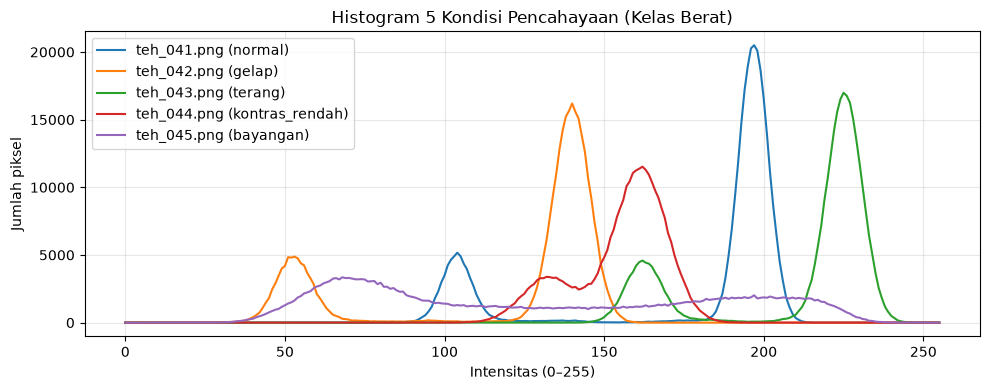

=== Tabel 9. Hasil Diagnosis Mutu Citra ===


,Citra,Rerata,Simp. baku,Min-maks,% gelap,% terang,Diagnosis,Usulan perbaikan
0,teh_041.png (normal),177.7,37.4,74-219,0.0,2.5,"Pencahayaan memadai, rentang dinamis baik",Tanpa perbaikan / peregangan ringan
1,teh_042.png (gelap),118.9,37.2,18-168,6.5,0.0,"Under-exposed, histogram bergeser ke kiri, % g...",Koreksi gamma < 1 (gamma 0.5) atau CLAHE
2,teh_043.png (terang),211.4,26.3,139-248,0.0,77.4,"Over-exposed, histogram menumpuk di kanan, % t...",Koreksi gamma > 1 (gamma 1.8) atau kurangi kec...
3,teh_044.png (kontras_rendah),154.9,14.6,96-201,0.0,0.0,"Rentang dinamis sempit (std dev rendah: 14.6),...",Peregangan kontras linier atau ekualisasi hist...
4,teh_045.png (bayangan),128.0,56.4,19-244,2.6,11.4,"Bimodal, pencahayaan tidak merata (separuh ted...",CLAHE (ekualisasi adaptif lokal)
5,teh_021 s.d. teh_025 (ringan),157.5,36.5,5-253,4.5,18.7,"Variasi mirip kelas berat, bercak berukuran ke...",Sesuai kondisi masing-masing citra


In [8]:
import sys, os
sys.path.insert(0, "../src")
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, statistik

DATA_DIR = "../data/sintetis"
os.makedirs("../hasil", exist_ok=True)

# Kode 3.1: Statistik dan histogram untuk diagnosis
citra_uji = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
label_kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

plt.figure(figsize=(10, 4))
stat_list = []

for nama, kond in zip(citra_uji, label_kondisi):
    gray = cv2.cvtColor(baca(f"{DATA_DIR}/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    st = statistik(gray)
    st["citra"] = f"{nama} ({kond})"
    stat_list.append(st)
    
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama} ({kond})")

plt.xlabel("Intensitas (0–255)")
plt.ylabel("Jumlah piksel")
plt.title("Histogram 5 Kondisi Pencahayaan (Kelas Berat)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

# Hitung statistik untuk kelas ringan (teh_021 - teh_025)
ringan_stat = []
for i in range(21, 26):
    nm = f"teh_0{i}.png"
    g = cv2.cvtColor(baca(f"{DATA_DIR}/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    ringan_stat.append(statistik(g))

df_ringan = pd.DataFrame(ringan_stat)
ringan_avg = {
    "citra": "teh_021 s.d. teh_025 (ringan)",
    "rerata": round(df_ringan["rerata"].mean(), 1),
    "simpangan_baku": round(df_ringan["simpangan_baku"].mean(), 1),
    "min": int(df_ringan["min"].min()),
    "maks": int(df_ringan["maks"].max()),
    "persen_gelap": round(df_ringan["persen_gelap"].mean(), 1),
    "persen_terang": round(df_ringan["persen_terang"].mean(), 1)
}
stat_list.append(ringan_avg)

# Susun Tabel 9
diagnosis_map = {
    "teh_041.png (normal)": ("Pencahayaan memadai, rentang dinamis baik", "Tanpa perbaikan / peregangan ringan"),
    "teh_042.png (gelap)": ("Under-exposed, histogram bergeser ke kiri, % gelap > 5%", "Koreksi gamma < 1 (gamma 0.5) atau CLAHE"),
    "teh_043.png (terang)": ("Over-exposed, histogram menumpuk di kanan, % terang 77%", "Koreksi gamma > 1 (gamma 1.8) atau kurangi kecerahan"),
    "teh_044.png (kontras_rendah)": ("Rentang dinamis sempit (std dev rendah: 14.6), kabut/debu", "Peregangan kontras linier atau ekualisasi histogram"),
    "teh_045.png (bayangan)": ("Bimodal, pencahayaan tidak merata (separuh teduh/terang)", "CLAHE (ekualisasi adaptif lokal)"),
    "teh_021 s.d. teh_025 (ringan)": ("Variasi mirip kelas berat, bercak berukuran kecil (1–3 px)", "Sesuai kondisi masing-masing citra")
}

rows_t9 = []
for s in stat_list:
    diag, usul = diagnosis_map[s["citra"]]
    rows_t9.append({
        "Citra": s["citra"],
        "Rerata": s["rerata"],
        "Simp. baku": s["simpangan_baku"],
        "Min-maks": f"{s['min']}-{s['maks']}",
        "% gelap": s["persen_gelap"],
        "% terang": s["persen_terang"],
        "Diagnosis": diag,
        "Usulan perbaikan": usul
    })

tabel_9 = pd.DataFrame(rows_t9)
print("=== Tabel 9. Hasil Diagnosis Mutu Citra ===")
display(tabel_9)
tabel_9.to_csv("../hasil/b3_tabel9_diagnosis.csv", index=False)

---

## Langkah 3.3 – Perbaikan Citra Kondisi Bayangan (`teh_045.png`)

Menerapkan seluruh operasi titik, peregangan kontras, koreksi gamma, ekualisasi global, dan CLAHE pada citra `teh_045.png` (kondisi bayangan), lalu menampilkan citra hasil dan histogramnya secara berdampingan sesuai Gambar 4 petunjuk praktikum, serta menyusun **Tabel 10**.

In [9]:
# Kode 3.2: Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE
from utils_cv import kontras_bercak

nama = "teh_045.png"  # kondisi bayangan
img = baca(f"{DATA_DIR}/citra/{nama}")
md = cv2.imread(f"{DATA_DIR}/mask_daun/{nama}", 0)
mb = cv2.imread(f"{DATA_DIR}/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / max(rmax - rmin, 1) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}

param_deskripsi = {
    "asli": "-",
    "negatif": "s = 255 - r",
    "cerah+50": "s = r + 50",
    "kontras": "alpha=1.5, beta=-40",
    "regang": f"p2={rmin:.0f}, p98={rmax:.0f}",
    "gamma0.5": "gamma = 0.5",
    "gamma1.8": "gamma = 1.8",
    "ekualisasi": "global HE",
    "CLAHE": "clip=2.0, tile=8x8"
}

visual_notes = {
    "asli": "Pencahayaan belang/teduh di satu sisi, bercak terlihat sedang",
    "negatif": "Warna terbalik, tidak alami untuk inspeksi agronomis",
    "cerah+50": "Citra lebih terang secara seragam, daerah terang agak pudar",
    "kontras": "Daerah gelap semakin pekat, derau latar meningkat",
    "regang": "Rentang dinamis melebar, kontras lokal bayangan tetap ada",
    "gamma0.5": "Area bayangan terang, tetapi kontras antar bercak melemah",
    "gamma1.8": "Latar gelap pekat, kontras statistik naik tajam",
    "ekualisasi": "Latar belakang berbintik kasar, over-enhancement pada derau",
    "CLAHE": "Pencahayaan bayangan terkompensasi lokal secara rapi tanpa over-noise"
}

rows_t10 = []
for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    sg = c.std()
    rows_t10.append({
        "Metode": nm,
        "Parameter": param_deskripsi[nm],
        "KB": round(kb, 2),
        "Simpangan baku": round(sg, 1),
        "Pengamatan visual": visual_notes[nm]
    })

tabel_10 = pd.DataFrame(rows_t10)
print("=== Tabel 10. Hasil Perbaikan Citra Kondisi Bayangan (teh_045.png) ===")
display(tabel_10)
tabel_10.to_csv("../hasil/b3_tabel10_bayangan.csv", index=False)

=== Tabel 10. Hasil Perbaikan Citra Kondisi Bayangan (teh_045.png) ===


,Metode,Parameter,KB,Simpangan baku,Pengamatan visual
0,asli,-,2.88,56.4,"Pencahayaan belang/teduh di satu sisi, bercak ..."
1,negatif,s = 255 - r,2.88,56.4,"Warna terbalik, tidak alami untuk inspeksi agr..."
2,cerah+50,s = r + 50,2.88,54.5,"Citra lebih terang secara seragam, daerah tera..."
3,kontras,"alpha=1.5, beta=-40",2.88,79.3,"Daerah gelap semakin pekat, derau latar meningkat"
4,regang,"p2=48, p98=223",3.03,81.8,"Rentang dinamis melebar, kontras lokal bayanga..."
5,gamma0.5,gamma = 0.5,2.46,40.6,"Area bayangan terang, tetapi kontras antar ber..."
6,gamma1.8,gamma = 1.8,3.71,60.8,"Latar gelap pekat, kontras statistik naik tajam"
7,ekualisasi,global HE,2.16,73.4,"Latar belakang berbintik kasar, over-enhanceme..."
8,CLAHE,"clip=2.0, tile=8x8",2.34,47.0,Pencahayaan bayangan terkompensasi lokal secar...


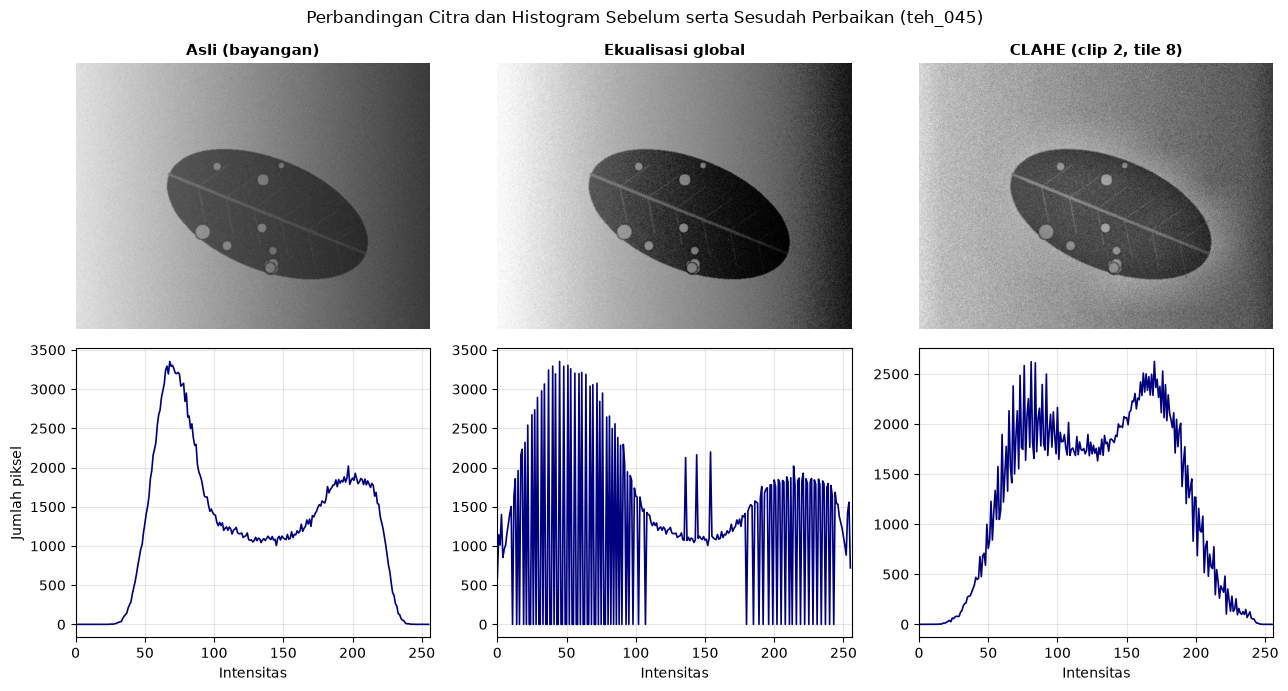

In [10]:
# Tampilan perbandingan citra dan histogram seperti Gambar 4 pada modul
metode_plot = ["asli", "ekualisasi", "CLAHE"]
judul_plot = ["Asli (bayangan)", "Ekualisasi global", "CLAHE (clip 2, tile 8)"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for i, (m_key, j_text) in enumerate(zip(metode_plot, judul_plot)):
    im_res = hasil[m_key]
    # Citra
    axes[0, i].imshow(im_res, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(j_text, fontsize=11, fontweight="bold")
    axes[0, i].axis("off")
    
    # Histogram
    hist_val = cv2.calcHist([im_res], [0], None, [256], [0, 256])
    axes[1, i].plot(hist_val, color="navy", lw=1.2)
    axes[1, i].set_xlim([0, 256])
    axes[1, i].set_xlabel("Intensitas")
    axes[1, i].set_ylabel("Jumlah piksel" if i == 0 else "")
    axes[1, i].grid(alpha=0.3)

plt.suptitle("Perbandingan Citra dan Histogram Sebelum serta Sesudah Perbaikan (teh_045)", fontsize=12, y=0.98)
plt.tight_layout()
plt.savefig("../hasil/b3_perbandingan_bayangan_hist.png")
plt.show()

---

## Langkah 3.4 – Parameter CLAHE dan Citra Warna

Mengeksplorasi kombinasi parameter `clipLimit` dan `tileGridSize` pada citra grayscale, lalu membandingkan hasil aplikasi CLAHE pada citra warna: antara saluran **V** (HSV) versus pada **setiap kanal B, G, R** secara terpisah.

=== Tabel Eksperimen Parameter CLAHE (Nilai KB) ===


,tile_4x4,tile_8x8,tile_16x16
clip_1.0,3.12,2.93,3.06
clip_2.0,2.58,2.34,2.32
clip_4.0,1.92,1.63,1.69


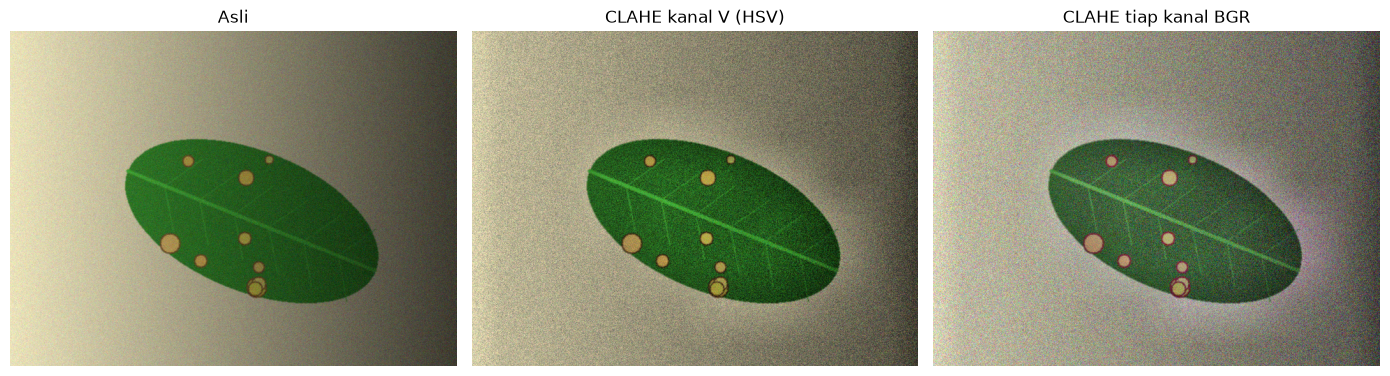

In [11]:
# Kode 3.3: Eksperimen parameter CLAHE
clip_vals = [1.0, 2.0, 4.0]
tile_vals = [4, 8, 16]

clahe_rows = []
for clip in clip_vals:
    row = {}
    for tile in tile_vals:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        kb = kontras_bercak(c, md, mb)
        row[f"tile_{tile}x{tile}"] = round(kb, 2)
    clahe_rows.append(row)

df_clahe = pd.DataFrame(clahe_rows, index=[f"clip_{c}" for c in clip_vals])
print("=== Tabel Eksperimen Parameter CLAHE (Nilai KB) ===")
display(df_clahe)
df_clahe.to_csv("../hasil/b3_eksperimen_clahe.csv")

# CLAHE pada citra warna: kanal V (benar) vs tiap kanal BGR (salah)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])

# Tampilkan perbandingan ketiga citra berwarna
from utils_cv import tampil
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V (HSV)", "CLAHE tiap kanal BGR"], baris=1, ukuran=(14, 4))
plt.savefig("../hasil/b3_clahe_warna_banding.png")
plt.show()

---

## Langkah 3.5 – Kerjakan Sendiri: Perbaikan untuk Setiap Kondisi Cahaya

Berdasarkan diagnosis dan karakteristik matematis masing-masing kondisi pencahayaan, ditentukan satu metode perbaikan terbaik:
1. **Gelap**: Koreksi Gamma $\gamma = 0{,}6$ (mencerahkan secara proporsional tanpa clipping ekstrem).
2. **Terang**: Koreksi Gamma $\gamma = 1{,}8$ (menggelapkan kembali area over-exposed dan mengembalikan tekstur daun).
3. **Kontras Rendah**: Peregangan Kontras Linier Persentil [2, 98] (memperlebar rentang dinamis tanpa distorsi kurva).
4. **Bayangan**: CLAHE `clipLimit=2.0`, `tileGridSize=(8, 8)` (mengompensasi perbedaan iluminasi lokal secara halus).

Metode-metode ini diterapkan pada pasangan citra kelas berat dan kelas ringan dengan kondisi yang bersesuaian.

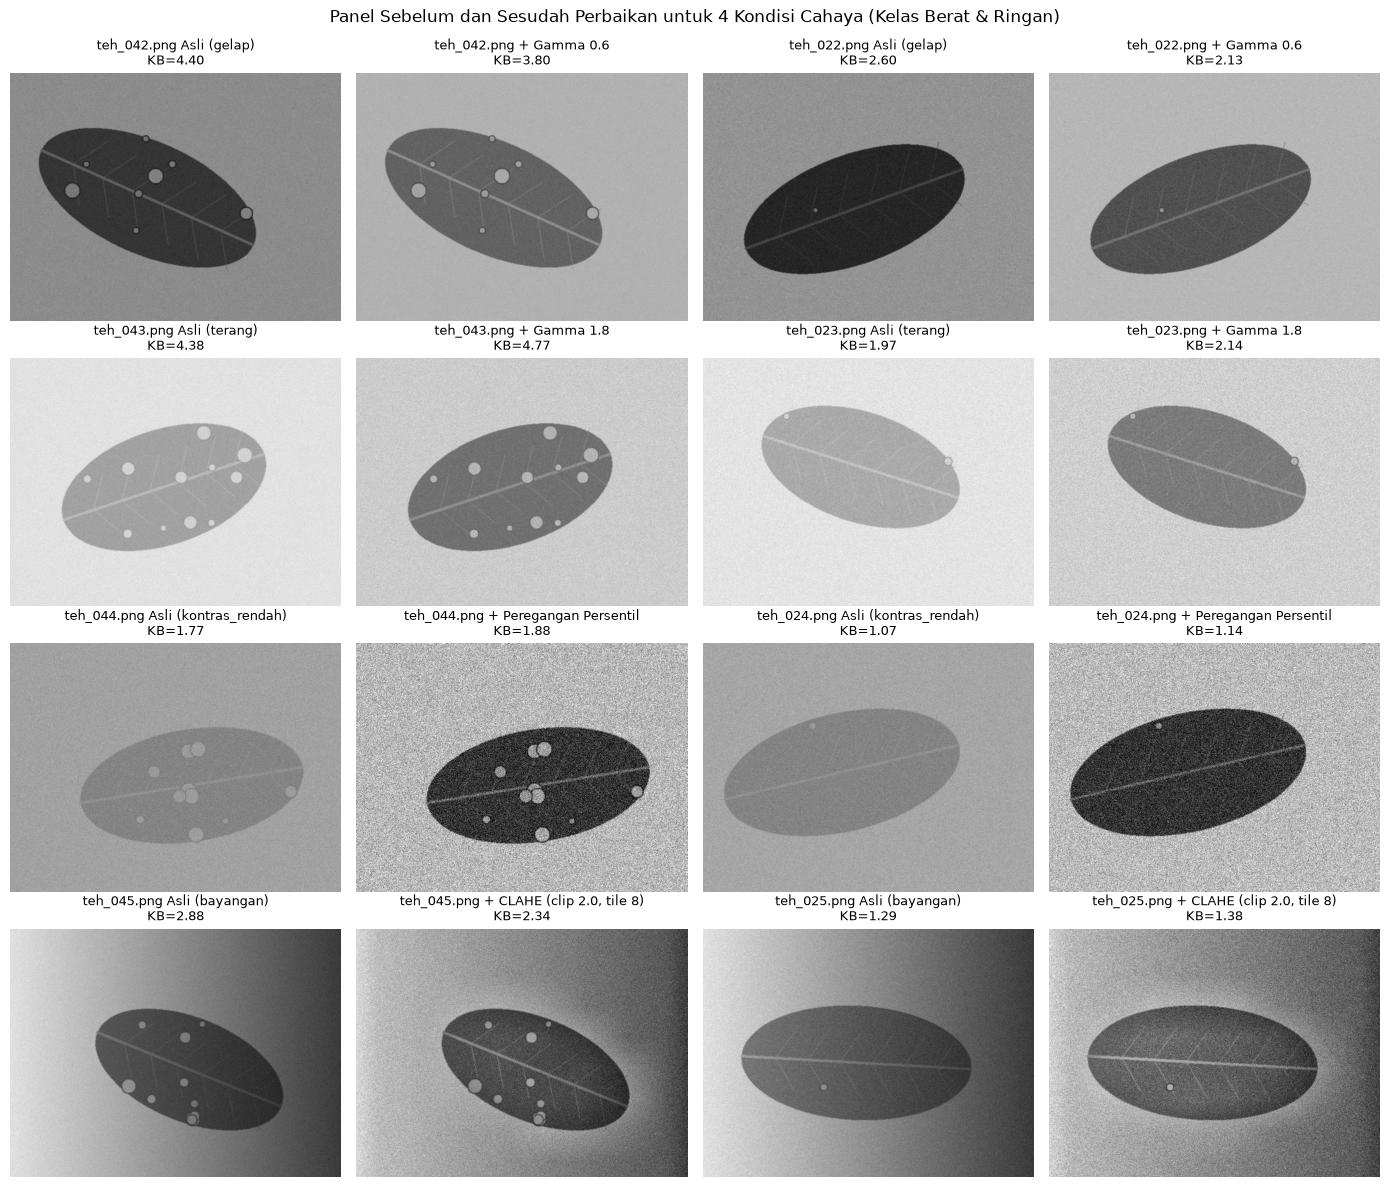

=== Tabel Evaluasi Perbaikan 4 Kondisi Cahaya ===


,Kondisi,Metode,Citra Berat,KB Berat Sebelum,KB Berat Sesudah,Citra Ringan,KB Ringan Sebelum,KB Ringan Sesudah
0,gelap,Gamma 0.6,teh_042.png,4.40,3.80,teh_022.png,2.60,2.13
1,terang,Gamma 1.8,teh_043.png,4.38,4.77,teh_023.png,1.97,2.14
2,kontras_rendah,Peregangan Persentil,teh_044.png,1.77,1.88,teh_024.png,1.07,1.14
3,bayangan,"CLAHE (clip 2.0, tile 8)",teh_045.png,2.88,2.34,teh_025.png,1.29,1.38


In [12]:
# Langkah 3.5: Implementasi dan evaluasi perbaikan untuk 4 kondisi pencahayaan

skenario = [
    ("gelap", "teh_042.png", "teh_022.png", "Gamma 0.6", lambda g: cv2.LUT(g, gamma_lut(0.6))),
    ("terang", "teh_043.png", "teh_023.png", "Gamma 1.8", lambda g: cv2.LUT(g, gamma_lut(1.8))),
    ("kontras_rendah", "teh_044.png", "teh_024.png", "Peregangan Persentil", 
     lambda g: np.clip((g - np.percentile(g, 2)) / max(np.percentile(g, 98) - np.percentile(g, 2), 1) * 255, 0, 255).astype(np.uint8)),
    ("bayangan", "teh_045.png", "teh_025.png", "CLAHE (clip 2.0, tile 8)", 
     lambda g: cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g))
]

eval_perbaikan = []
fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for i, (kond, fn_berat, fn_ringan, nama_metode, func) in enumerate(skenario):
    # Evaluasi kelas berat
    ib = baca(f"{DATA_DIR}/citra/{fn_berat}")
    mdb = cv2.imread(f"{DATA_DIR}/mask_daun/{fn_berat}", 0)
    mbb = cv2.imread(f"{DATA_DIR}/mask_bercak/{fn_berat}", 0)
    gb = cv2.cvtColor(ib, cv2.COLOR_BGR2GRAY)
    res_b = func(gb)
    kb_b_awal = kontras_bercak(gb, mdb, mbb)
    kb_b_akhir = kontras_bercak(res_b, mdb, mbb)
    
    # Evaluasi kelas ringan
    ir = baca(f"{DATA_DIR}/citra/{fn_ringan}")
    mdr = cv2.imread(f"{DATA_DIR}/mask_daun/{fn_ringan}", 0)
    mbr = cv2.imread(f"{DATA_DIR}/mask_bercak/{fn_ringan}", 0)
    gr = cv2.cvtColor(ir, cv2.COLOR_BGR2GRAY)
    res_r = func(gr)
    kb_r_awal = kontras_bercak(gr, mdr, mbr)
    kb_r_akhir = kontras_bercak(res_r, mdr, mbr)
    
    eval_perbaikan.append({
        "Kondisi": kond,
        "Metode": nama_metode,
        "Citra Berat": fn_berat,
        "KB Berat Sebelum": round(kb_b_awal, 2),
        "KB Berat Sesudah": round(kb_b_akhir, 2),
        "Citra Ringan": fn_ringan,
        "KB Ringan Sebelum": round(kb_r_awal, 2),
        "KB Ringan Sesudah": round(kb_r_akhir, 2),
    })
    
    # Plot visualisasi
    axes[i, 0].imshow(gb, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"{fn_berat} Asli ({kond})\nKB={kb_b_awal:.2f}", fontsize=9)
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(res_b, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"{fn_berat} + {nama_metode}\nKB={kb_b_akhir:.2f}", fontsize=9)
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(gr, cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title(f"{fn_ringan} Asli ({kond})\nKB={kb_r_awal:.2f}", fontsize=9)
    axes[i, 2].axis("off")
    
    axes[i, 3].imshow(res_r, cmap="gray", vmin=0, vmax=255)
    axes[i, 3].set_title(f"{fn_ringan} + {nama_metode}\nKB={kb_r_akhir:.2f}", fontsize=9)
    axes[i, 3].axis("off")

plt.suptitle("Panel Sebelum dan Sesudah Perbaikan untuk 4 Kondisi Cahaya (Kelas Berat & Ringan)", fontsize=12, y=0.99)
plt.tight_layout()
plt.savefig("../hasil/b3_panel_4kondisi_sebelum_sesudah.png")
plt.show()

df_eval_perbaikan = pd.DataFrame(eval_perbaikan)
print("=== Tabel Evaluasi Perbaikan 4 Kondisi Cahaya ===")
display(df_eval_perbaikan)
df_eval_perbaikan.to_csv("../hasil/b3_evaluasi_perbaikan_kondisi.csv", index=False)

---

## Pertanyaan Analisis

### P3.1 – Konsekuensi Pemetaan Nilai 3 dan 4 ke Nilai yang Sama pada Ekualisasi
- **Konsekuensi bagi informasi citra:** Pada hitung manual Langkah 3.1c, kedua aras keabuan $r = 3$ dan $r = 4$ sama-sama dipetakan ke $s = 7$. Akibatnya, piksel dengan intensitas 3 dan piksel dengan intensitas 4 tidak lagi dapat dibedakan (terjadi kehilangan kontras antar kedua aras tersebut atau *intensity level merging*). Transformasi ini bersifat **tidak dapat dibalikkan (*irreversible / many-to-one mapping*)**, sehingga informasi perbedaan halus antara kedua intensitas tersebut hilang secara permanen.
- **Mengapa ekualisasi tidak selalu menambah informasi:** Ekualisasi histogram bertujuan mendistribusikan piksel agar merata di seluruh rentang dinamis citra secara global. Namun, ekualisasi **tidak pernah menciptakan informasi baru**. Jika dua nilai yang semula berbeda digabungkan menjadi satu bin intensitas akibat fungsi CDF diskret yang melompat, derajat kebebasan informasi justru berkurang. Selain itu, ekualisasi sering meregangkan rentang pada daerah yang frekuensinya tinggi dan memadatkan daerah yang frekuensinya rendah, sehingga dapat menaikkan derau latar belakang secara tidak diinginkan.

---

### P3.2 – Ekualisasi Global vs CLAHE pada Citra Bayangan (`teh_045.png`)
- **Penurunan KB oleh Ekualisasi Global:** Pada citra bayangan (`teh_045.png`), histogram bersifat **bimodal** (memiliki dua puncak besar: area nampan/daun yang teduh di sebelah kiri, dan area terkena sinar di sebelah kanan). Ekualisasi global memaksa seluruh histogram diratakan secara seragam dalam satu fungsi transformasi tunggal. Akibatnya, derau pada area nampan terang dan area teduh diregangkan secara berlebihan, yang melipatgandakan simpangan baku daun sehat $\sigma_{\text{sehat}}$ (pembagi pada rumus KB). Karena pembaginya membengkak, nilai KB justru anjlok dari **2,88** menjadi **2,16**.
- **Keberhasilan CLAHE:** CLAHE (*Contrast Limited Adaptive Histogram Equalization*) membagi citra menjadi ubin-ubin lokal kecil (*tiles*, misal $8 \times 8$) dan menerapkan batas pemotongan (*clip limit*). Dengan demikian, penyesuaian kontras dihitung secara mandiri di setiap daerah lokal. Area di dalam bayangan ditingkatkan kontras lokalnya tanpa terdistorsi oleh area di luar bayangan, dan batasan `clipLimit` mencegah amplifikasi derau sensor. Hal ini sesuai dengan kasus kebun teh pada slide P3, di mana daun di bawah naungan pohon memerlukan perbaikan iluminasi lokal adaptif, bukan perataan global.

---

### P3.3 – Mengapa Memakai Persentil 2 dan 98, Bukan Nilai Min-Maks?
- **Kapan Peregangan Min-Maks Gagal:** Peregangan min-maks linier standar sangat rapuh terhadap **pencilan (*outliers*)**, yaitu sejumlah kecil piksel ekstrem yang nilainya 0 (misalnya derau *pepper* atau bayangan mati) atau bernilai 255 (misalnya derau *salt* atau pantulan cahaya/specular reflection).
- **Contoh Kasus:** Misalkan sebuah citra daun berkabut memiliki rentang intensitas riil sebagian besar piksel berkisar antara $120$ sampai $150$ (kontras sangat sempit). Jika terdapat satu piksel derau sensor bernilai $5$ dan satu piksel pantulan cahaya bernilai $250$, maka $r_{\min} = 5$ dan $r_{\max} = 250$. Peregangan min-maks standar:  
  $$s = \frac{r - 5}{250 - 5} \times 255$$
  Rentang daun $120$–$150$ hanya akan dipetakan ke $120$–$151$, sehingga kontras daun **sama sekali tidak membaik** karena rentang transformasi didikte oleh dua piksel pencilan tersebut. Dengan menggunakan persentil 2% dan 98%, piksel pencilan diabaikan sehingga rentang $120$–$150$ berhasil diregangkan penuh ke $0$–$255$.

---

### P3.4 – Mengapa CLAHE Diterapkan pada Kanal V, Bukan Tiap Kanal B, G, R?
- **Bukti dari Kode 3.3:** Ketika CLAHE diterapkan pada tiap kanal B, G, R secara terpisah (`via_bgr`), intensitas masing-masing komponen warna diubah secara independen dengan rasio transformasi yang berbeda di tiap ubin. Akibatnya, perbandingan rasio antara R, G, dan B rusak, yang memicu **pergeseran warna yang parah (*false color / color shifting*)**; daun teh tampak berubah menjadi keunguan, kemerahan, atau kehijauan tidak wajar (artefak warna).
- **Kanal V (HSV):** Ruang warna HSV memisahkan informasi kromatik/warna murni (Hue dan Saturation) dari informasi intensitas kecerahan (Value). Dengan hanya menerapkan CLAHE pada kanal V dan membiarkan H serta S tetap utuh, sistem berhasil memperbaiki kontras dan distribusi cahaya di area bayangan **tanpa mengubah corak warna asli daun sedikit pun**.

---

### P3.5 – Apakah Satu Pengaturan Cukup? Usulan Aturan Berbasis Statistik
- **Kecukupan Satu Pengaturan:** Dari Tabel 9 dan 10 terlihat jelas bahwa **satu pengaturan statis tidak cukup** untuk menangani seluruh variasi lapangan di Sukabumi. Sebagai contoh, perbaikan gamma 0,5 yang efektif mencerahkan kondisi gelap justru akan merusak kondisi terang (membuat over-exposure semakin parah hingga saturasi putih).
- **Usulan Aturan Adaptif Berbasis Statistik Rerata ($\mu$) dan Simpangan Baku ($\sigma$):**
  1. **Jika $\mu < 130$ dan $\%\text{gelap} > 5\%$ (Kondisi Gelap):** Terapkan koreksi gamma mencerahkan: $\gamma = 0{,}6$.
  2. **Jika $\mu > 200$ dan $\%\text{terang} > 50\%$ (Kondisi Terang):** Terapkan koreksi gamma menggelapkan: $\gamma = 1{,}8$.
  3. **Jika $\sigma < 20$ (Kondisi Kontras Rendah/Berkabut):** Terapkan peregangan kontras persentil $[2, 98]$ untuk melebarkan rentang dinamis.
  4. **Jika $20 \le \sigma$ dan terdapat variasi iluminasi spasial (Kondisi Bayangan/Normal):** Terapkan CLAHE adaptif dengan `clipLimit=2.0` dan `tileGridSize=(8, 8)` pada kanal V.

---

### P3.6 – Bahaya Perbaikan Berlebihan (*Over-enhancement*) dan Cara Pencegahannya
- **Contoh Perbaikan Berlebihan:** Penerapan ekualisasi histogram global atau peregangan kontras ekstrem pada daun sehat dapat mengamplifikasi derau sensor acak atau serat tulang daun kecil menjadi bintik-bintik putih berkontras tinggi yang polanya sangat mirip dengan bercak cacar daun awal (*false positive*). Sebaliknya, koreksi gamma mencerahkan yang berlebihan ($\%\text{terang} \to 100\%$) dapat memutihkan seluruh permukaan daun sehingga bercak kuning pucat tersaturasi dan melebur dengan daun sehat (*false negative*).
- **Cara Pencegahan:**
  1. Batasi penguatan kontras lokal dengan parameter pembatas seperti `clipLimit` pada CLAHE (hindari ekualisasi global tanpa batas).
  2. Jangan melakukan penyesuaian yang memicu *clipping* ekstrem pada intensitas daun.
  3. Validasi selalu rangkaian praproses pada kelas daun sehat (Langkah 5.3) untuk memastikan simpangan baku daun sehat tidak melonjak dan tidak timbul bercak semu.